# TerraMind Similarity Heatmaps

This notebook implements interactive reference selection and multi-measure similarity heatmaps for TerraMind latent embeddings.

In [29]:
# Notebook environment setup (idempotent)
# If dependencies are not already installed in this uv project, run:
# !uv add torch numpy pandas matplotlib scipy scikit-learn ipympl ipywidgets tqdm
# !uv sync

Resolved 140 packages in 855ms                                       
Audited 136 packages in 2ms                                          
Resolved 140 packages in 1ms
Audited 136 packages in 3ms


In [1]:
from __future__ import annotations

from pathlib import Path
import importlib.util
import json
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from matplotlib.widgets import LassoSelector
from scipy.stats import rankdata, spearmanr
import torch

# Tunable parameters (single source of truth)
DATA_PATH = Path("../data/latents_0_92160.pt")
DEFAULT_MEASURE = "cosine"  # cosine | angular | dot | mahalanobis
TOP_K_PERCENTILE = 5
REGION_SELECTION_COLOR = "tab:orange"
FIGSIZE = (14, 10)

USE_MEDOID_FOR_REGION = False
WORLD_GEOJSON_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
CACHE_DIR = Path("../data/cache")
WORLD_GEOJSON_CACHE = CACHE_DIR / "ne_110m_admin_0_countries.geojson"
EXPORT_DIR = Path("../data/similarity_exports")
BIOME_PATH = None  # Optional path to a biome annotation file

CACHE_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
np.set_printoptions(precision=4, suppress=True)

# Keep rendering reliable for all cells: inline by default.
INTERACTIVE_BACKEND = "inline"
ip = get_ipython()
if ip is not None:
    ip.run_line_magic("matplotlib", "inline")

def activate_interactive_backend() -> str:
    global INTERACTIVE_BACKEND
    if ip is None:
        INTERACTIVE_BACKEND = "inline"
        return INTERACTIVE_BACKEND

    if importlib.util.find_spec("ipympl") is not None and importlib.util.find_spec("ipywidgets") is not None:
        ip.run_line_magic("matplotlib", "widget")
        INTERACTIVE_BACKEND = "widget"
        return INTERACTIVE_BACKEND

    ip.run_line_magic("matplotlib", "inline")
    INTERACTIVE_BACKEND = "inline"
    warnings.warn(
        "ipympl + ipywidgets not found, so interactive cells run in static mode. Install with: uv add ipympl ipywidgets",
        stacklevel=2,
    )
    return INTERACTIVE_BACKEND

## 1. Environment & Data

Data path: ../data/latents_0_92160.pt
N=92,160, d=192
lat range: [-54.6914, 80.8289] | lon range: [-175.0968, 179.8459]
Cached E_norm -> ../data/cache/latents_0_92160_E_norm.npy
Cached Sigma, Sigma_inv -> ../data/cache/latents_0_92160_Sigma.npy, ../data/cache/latents_0_92160_Sigma_inv.npy


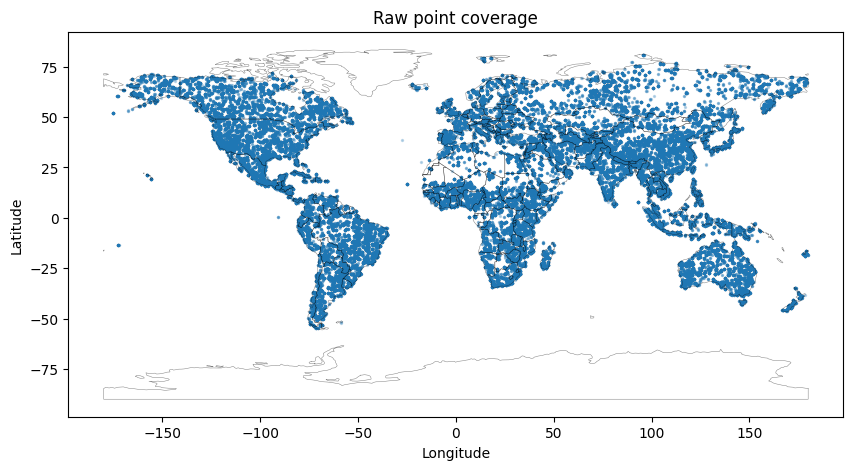

In [2]:
def resolve_data_path(path: Path) -> Path:
    candidates = [path, Path("data/latents_0_92160.pt"), Path("../data/latents_0_92160.pt")]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Could not find latent file. Tried: {[str(c) for c in candidates]}")


data_path = resolve_data_path(DATA_PATH)

# TODO: support multi-shard loading via glob (e.g. latents_0_*.pt).
obj = torch.load(data_path, map_location="cpu", weights_only=False)

if isinstance(obj, pd.DataFrame):
    df = obj.copy()
elif isinstance(obj, dict) and {"latents", "meta"}.issubset(obj.keys()):
    latents = obj["latents"]
    meta = obj["meta"]
    if isinstance(latents, torch.Tensor):
        latents = latents.detach().cpu().numpy()
    else:
        latents = np.asarray(latents)
    if isinstance(meta, torch.Tensor):
        meta = meta.detach().cpu().numpy()
    else:
        meta = np.asarray(meta)
    if meta.ndim != 2 or meta.shape[1] < 2:
        raise ValueError(f"Expected meta with at least 2 columns (lat, lon), got shape {meta.shape}")
    if latents.shape[0] != meta.shape[0]:
        raise ValueError(f"latents/meta row mismatch: {latents.shape[0]} vs {meta.shape[0]}")
    df = pd.DataFrame(
        {
            "lat": meta[:, 0],
            "lon": meta[:, 1],
            "latent": [latents[i] for i in range(latents.shape[0])],
        }
    )
elif isinstance(obj, dict) and {"lat", "lon", "latent"}.issubset(obj.keys()):
    df = pd.DataFrame(obj)
elif isinstance(obj, list):
    df = pd.DataFrame(obj)
else:
    raise TypeError(f"Unsupported payload type from torch.load: {type(obj)}")

required_cols = {"lat", "lon", "latent"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

def to_numpy_vec(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

df["latent"] = df["latent"].apply(to_numpy_vec)

first_valid_idx = next((i for i, v in enumerate(df["latent"].values) if np.asarray(v).size > 0), None)
if first_valid_idx is None:
    raise ValueError("No non-empty latent vectors found")

d = int(np.asarray(df["latent"].iloc[first_valid_idx]).reshape(-1).shape[0])

def normalize_shape(v):
    a = np.asarray(v).reshape(-1)
    if a.shape[0] != d:
        raise ValueError(f"Inconsistent latent dimension. Expected {d}, got {a.shape[0]}")
    return a

df["latent"] = df["latent"].apply(normalize_shape)

E = np.vstack(df["latent"].values).astype(np.float32, copy=False)
lats = df["lat"].to_numpy(np.float64)
lons = df["lon"].to_numpy(np.float64)

if np.isnan(lats).any() or np.isnan(lons).any() or np.isnan(E).any():
    raise ValueError("Found NaNs in lat/lon/latent arrays")

print(f"Data path: {data_path}")
print(f"N={E.shape[0]:,}, d={E.shape[1]}")
print(f"lat range: [{lats.min():.4f}, {lats.max():.4f}] | lon range: [{lons.min():.4f}, {lons.max():.4f}]")

E_norm_cache = CACHE_DIR / f"{data_path.stem}_E_norm.npy"
Sigma_cache = CACHE_DIR / f"{data_path.stem}_Sigma.npy"
Sigma_inv_cache = CACHE_DIR / f"{data_path.stem}_Sigma_inv.npy"

if E_norm_cache.exists():
    E_norm = np.load(E_norm_cache)
else:
    norms = np.linalg.norm(E, axis=1, keepdims=True)
    E_norm = E / np.clip(norms, 1e-12, None)
    np.save(E_norm_cache, E_norm)

if Sigma_cache.exists() and Sigma_inv_cache.exists():
    Sigma = np.load(Sigma_cache)
    Sigma_inv = np.load(Sigma_inv_cache)
else:
    Sigma = np.cov(E, rowvar=False)
    Sigma_inv = np.linalg.pinv(Sigma)
    np.save(Sigma_cache, Sigma)
    np.save(Sigma_inv_cache, Sigma_inv)

print(f"Cached E_norm -> {E_norm_cache}")
print(f"Cached Sigma, Sigma_inv -> {Sigma_cache}, {Sigma_inv_cache}")

# Shared notebook-scope state used by later sections.
selected_idx = 0
ref_vector = E[selected_idx].copy()
region_indices = np.array([], dtype=np.int64)
region_vectors = np.empty((0, E.shape[1]), dtype=E.dtype)
lasso_vertices = None

def _flatten_geojson_segments(geometry: dict):
    gtype = geometry.get("type")
    coords = geometry.get("coordinates", [])
    segments = []
    if gtype == "Polygon":
        polygons = [coords]
    elif gtype == "MultiPolygon":
        polygons = coords
    else:
        return segments
    for poly in polygons:
        for ring in poly:
            arr = np.asarray(ring, dtype=np.float64)
            if arr.ndim == 2 and arr.shape[1] >= 2:
                segments.append(arr[:, :2])
    return segments

def load_world_segments(cache_path: Path = WORLD_GEOJSON_CACHE, url: str = WORLD_GEOJSON_URL):
    if not cache_path.exists():
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, cache_path)
    with cache_path.open("r", encoding="utf-8") as f:
        data = json.load(f)
    segments = []
    for feature in data.get("features", []):
        geom = feature.get("geometry")
        if geom is None:
            continue
        segments.extend(_flatten_geojson_segments(geom))
    return segments

WORLD_SEGMENTS = load_world_segments()

def draw_world_outline(ax, linewidth: float = 0.35, alpha: float = 0.5, color: str = "black"):
    for seg in WORLD_SEGMENTS:
        ax.plot(seg[:, 0], seg[:, 1], color=color, linewidth=linewidth, alpha=alpha)
    return ax

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(lons, lats, s=2, alpha=0.25, color="tab:blue")
draw_world_outline(ax)
ax.set_title("Raw point coverage")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

## 2. Similarity Functions

In [3]:
def l2_normalize_rows(mat: np.ndarray) -> np.ndarray:
    norms = np.linalg.norm(mat, axis=1, keepdims=True)
    return mat / np.clip(norms, 1e-12, None)

def cosine_similarity(ref: np.ndarray, E_norm: np.ndarray) -> np.ndarray:
    ref = np.asarray(ref).reshape(-1)
    ref_norm = ref / np.clip(np.linalg.norm(ref), 1e-12, None)
    return E_norm @ ref_norm

def angular_distance(ref: np.ndarray, E_norm: np.ndarray) -> np.ndarray:
    cos = np.clip(cosine_similarity(ref, E_norm), -1.0, 1.0)
    return np.arccos(cos)

def dot_product(ref: np.ndarray, E: np.ndarray) -> np.ndarray:
    ref = np.asarray(ref).reshape(-1)
    return E @ ref

def mahalanobis_distance(ref: np.ndarray, E: np.ndarray, Sigma_inv: np.ndarray) -> np.ndarray:
    ref = np.asarray(ref).reshape(1, -1)
    diff = E - ref
    dist_sq = np.einsum("ij,jk,ik->i", diff, Sigma_inv, diff)
    return np.sqrt(np.clip(dist_sq, 0.0, None))

def percentile_normalize(scores: np.ndarray) -> np.ndarray:
    ranks = rankdata(scores, method="average")
    if len(scores) <= 1:
        return np.zeros_like(scores, dtype=np.float64)
    return (ranks - 1) / (len(scores) - 1)

def measure_similarity_field(
    ref: np.ndarray,
    measure: str = DEFAULT_MEASURE,
    *,
    return_raw: bool = False,
) -> np.ndarray | tuple[np.ndarray, np.ndarray]:
    key = measure.lower()
    if key == "cosine":
        raw = cosine_similarity(ref, E_norm)
        sim = raw
    elif key == "angular":
        raw = angular_distance(ref, E_norm)
        sim = -raw
    elif key == "dot":
        raw = dot_product(ref, E)
        sim = raw
    elif key == "mahalanobis":
        raw = mahalanobis_distance(ref, E, Sigma_inv)
        sim = -raw
    else:
        raise ValueError(f"Unknown measure: {measure}")
    if return_raw:
        return sim, raw
    return sim

def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(lat1)
    lon1 = np.deg2rad(lon1)
    lat2 = np.deg2rad(lat2)
    lon2 = np.deg2rad(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2.0 * np.arcsin(np.clip(np.sqrt(a), 0.0, 1.0))
    return 6371.0 * c

# TODO: add CKA-based similarity for neighborhood patches.

## 3. Interactive Point Selection

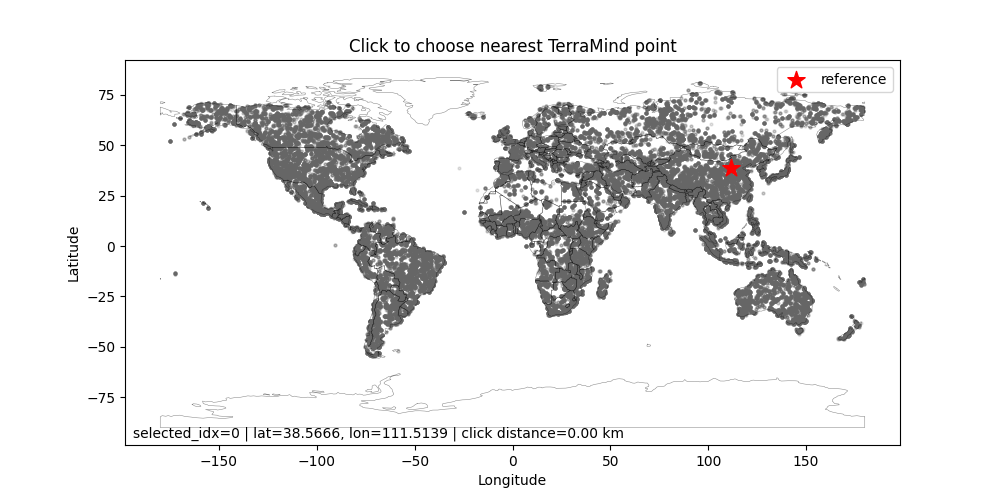

In [4]:
def find_nearest_index_by_haversine(click_lat: float, click_lon: float) -> tuple[int, float]:
    dists_km = haversine_km(click_lat, click_lon, lats, lons)
    idx = int(np.argmin(dists_km))
    return idx, float(dists_km[idx])

def launch_point_picker():
    backend = activate_interactive_backend()
    if backend == "inline":
        warnings.warn("Point picker is static because interactive backend is unavailable.", stacklevel=2)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(lons, lats, s=4, alpha=0.18, color="0.4")
    draw_world_outline(ax)
    marker = ax.scatter([lons[selected_idx]], [lats[selected_idx]], marker="*", s=170, color="red", label="reference")
    status_text = ax.text(0.01, 0.01, "", transform=ax.transAxes, va="bottom", ha="left")
    ax.set_title("Click to choose nearest TerraMind point")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(loc="upper right")

    def update_status(idx: int, dist_km: float):
        status_text.set_text(
            f"selected_idx={idx} | lat={lats[idx]:.4f}, lon={lons[idx]:.4f} | click distance={dist_km:.2f} km"
        )

    update_status(selected_idx, 0.0)

    def on_click(event):
        global selected_idx, ref_vector
        if event.inaxes != ax or event.xdata is None or event.ydata is None:
            return
        idx, dist_km = find_nearest_index_by_haversine(float(event.ydata), float(event.xdata))
        selected_idx = idx
        ref_vector = E[selected_idx].copy()
        marker.set_offsets(np.array([[lons[selected_idx], lats[selected_idx]]]))
        update_status(selected_idx, dist_km)
        fig.canvas.draw_idle()
        print(f"Selected idx={selected_idx}, lat={lats[selected_idx]:.4f}, lon={lons[selected_idx]:.4f}")

    cid = fig.canvas.mpl_connect("button_press_event", on_click)
    plt.show()
    return fig, ax, cid

picker_fig, picker_ax, picker_cid = launch_point_picker()

# TODO: add dropdown to select reference by biome label (requires annotation file).

## 4. Interactive Region Selection

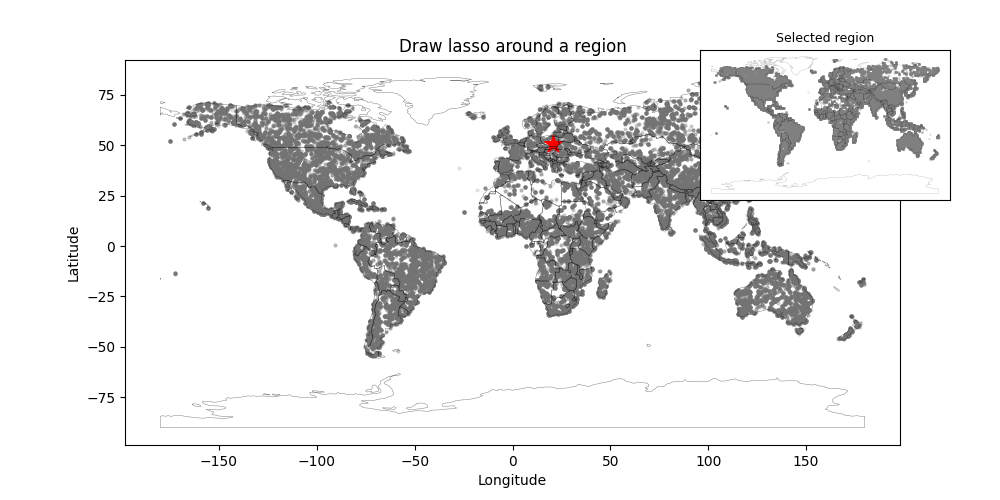

In [5]:
def _reference_from_region(vectors: np.ndarray, use_medoid: bool = False) -> tuple[np.ndarray, str]:
    mean_vec = vectors.mean(axis=0)
    mean_unit = mean_vec / np.clip(np.linalg.norm(mean_vec), 1e-12, None)
    if not use_medoid:
        return mean_unit, "mean"
    vectors_unit = l2_normalize_rows(vectors)
    medoid_local_idx = int(np.argmax(vectors_unit @ mean_unit))
    return vectors[medoid_local_idx], "medoid"

def launch_region_selector(use_medoid: bool = USE_MEDOID_FOR_REGION):
    global region_indices, region_vectors, ref_vector, selected_idx, lasso_vertices
    backend = activate_interactive_backend()
    if backend == "inline":
        warnings.warn("Lasso selector is static because interactive backend is unavailable.", stacklevel=2)

    coords = np.column_stack([lons, lats])
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(lons, lats, s=4, alpha=0.15, color="0.45")
    draw_world_outline(ax)
    selected_scatter = ax.scatter([], [], s=11, alpha=0.9, color=REGION_SELECTION_COLOR)
    ref_marker = ax.scatter([lons[selected_idx]], [lats[selected_idx]], marker="*", s=170, color="red")
    polygon_line, = ax.plot([], [], color=REGION_SELECTION_COLOR, linewidth=2)

    ax.set_title("Draw lasso around a region")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    inset_ax = fig.add_axes([0.70, 0.60, 0.25, 0.30])
    inset_ax.scatter(lons, lats, s=1, alpha=0.10, color="0.5")
    draw_world_outline(inset_ax, linewidth=0.2, alpha=0.35)
    inset_selected = inset_ax.scatter([], [], s=6, alpha=0.95, color=REGION_SELECTION_COLOR)
    inset_ax.set_xticks([])
    inset_ax.set_yticks([])
    inset_ax.set_title("Selected region", fontsize=9)

    def on_select(verts):
        global region_indices, region_vectors, ref_vector, selected_idx, lasso_vertices
        lasso_vertices = np.asarray(verts, dtype=np.float64)
        mask = MplPath(lasso_vertices).contains_points(coords)
        idx = np.flatnonzero(mask)
        if idx.size == 0:
            print("Lasso selection is empty. Draw again.")
            return

        region_indices = idx.astype(np.int64)
        region_vectors = E[region_indices]
        if region_indices.size > 500:
            warnings.warn("Large K in region selection; (K, N) similarity matrix can be memory intensive.", stacklevel=2)

        ref_vector, mode = _reference_from_region(region_vectors, use_medoid=use_medoid)
        ref_unit = ref_vector / np.clip(np.linalg.norm(ref_vector), 1e-12, None)
        representative_local_idx = int(np.argmax(l2_normalize_rows(region_vectors) @ ref_unit))
        selected_idx = int(region_indices[representative_local_idx])

        sel_lonlat = np.column_stack([lons[region_indices], lats[region_indices]])
        selected_scatter.set_offsets(sel_lonlat)
        inset_selected.set_offsets(sel_lonlat)
        ref_marker.set_offsets(np.array([[lons[selected_idx], lats[selected_idx]]]))

        closed = np.vstack([lasso_vertices, lasso_vertices[0]])
        polygon_line.set_data(closed[:, 0], closed[:, 1])
        fig.canvas.draw_idle()

        lat_min, lat_max = lats[region_indices].min(), lats[region_indices].max()
        lon_min, lon_max = lons[region_indices].min(), lons[region_indices].max()
        print(
            f"Selected K={region_indices.size} vectors | lat=[{lat_min:.4f}, {lat_max:.4f}] "
            f"lon=[{lon_min:.4f}, {lon_max:.4f}] | reference mode={mode}"
        )

    lasso = LassoSelector(ax, on_select, useblit=True, button=1)
    plt.show()
    return fig, ax, lasso

lasso_fig, lasso_ax, lasso_tool = launch_region_selector(use_medoid=USE_MEDOID_FOR_REGION)

# TODO: add RectangleSelector as an axis-aligned alternative.

## 5. Group Similarity Averaging

Data flow: Cell 3 sets `selected_idx` / `ref_vector`; Cell 4 sets `region_indices` / `region_vectors` / `lasso_vertices`. This section compares two group-reference modes:
1. centroid reference (`mean(region_vectors)`) against full dataset;
2. averaged field (`mean_k sim(v_k, E)`), which preserves within-region spread.

In [6]:
def group_similarity_matrix(region_vectors: np.ndarray, measure: str = DEFAULT_MEASURE) -> np.ndarray:
    if region_vectors.shape[0] == 0:
        raise ValueError("No vectors selected. Use the lasso selector first.")

    key = measure.lower()
    if key == "cosine":
        R = l2_normalize_rows(region_vectors)
        return R @ E_norm.T
    if key == "angular":
        R = l2_normalize_rows(region_vectors)
        cos = np.clip(R @ E_norm.T, -1.0, 1.0)
        return -np.arccos(cos)
    if key == "dot":
        return region_vectors @ E.T
    if key == "mahalanobis":
        RS = region_vectors @ Sigma_inv
        r_quad = np.einsum("ij,ij->i", RS, region_vectors)
        XS = E @ Sigma_inv
        x_quad = np.einsum("ij,ij->i", XS, E)
        cross = RS @ E.T
        dist_sq = r_quad[:, None] + x_quad[None, :] - 2.0 * cross
        return -np.sqrt(np.clip(dist_sq, 0.0, None))
    raise ValueError(f"Unknown measure: {measure}")

def centroid_similarity_field(region_vectors: np.ndarray, measure: str = DEFAULT_MEASURE) -> np.ndarray:
    centroid = region_vectors.mean(axis=0)
    return measure_similarity_field(centroid, measure=measure)

def averaged_group_similarity_field(
    region_vectors: np.ndarray,
    measure: str = DEFAULT_MEASURE,
    aggregation: str = "mean",
) -> np.ndarray:
    K = region_vectors.shape[0]
    if K > 500:
        warnings.warn("K > 500 can require substantial RAM for a full (K, N) matrix.", stacklevel=2)
    mat = group_similarity_matrix(region_vectors, measure=measure)
    if aggregation == "mean":
        return mat.mean(axis=0)
    if aggregation == "median":
        return np.median(mat, axis=0)
    raise ValueError("aggregation must be one of: mean, median")

def plot_group_mode_comparison(region_vectors: np.ndarray, measure: str = DEFAULT_MEASURE):
    centroid_field = centroid_similarity_field(region_vectors, measure=measure)
    averaged_field = averaged_group_similarity_field(region_vectors, measure=measure, aggregation="mean")

    vmin = float(min(centroid_field.min(), averaged_field.min()))
    vmax = float(max(centroid_field.max(), averaged_field.max()))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

    sc0 = axes[0].scatter(lons, lats, c=centroid_field, s=5, cmap="magma", vmin=vmin, vmax=vmax)
    draw_world_outline(axes[0])
    axes[0].scatter(lons[region_indices], lats[region_indices], s=8, color=REGION_SELECTION_COLOR, alpha=0.6)
    axes[0].set_title(f"Centroid reference ({measure})")
    axes[0].set_xlabel("Longitude")
    axes[0].set_ylabel("Latitude")
    fig.colorbar(sc0, ax=axes[0], shrink=0.9)

    sc1 = axes[1].scatter(lons, lats, c=averaged_field, s=5, cmap="magma", vmin=vmin, vmax=vmax)
    draw_world_outline(axes[1])
    axes[1].scatter(lons[region_indices], lats[region_indices], s=8, color=REGION_SELECTION_COLOR, alpha=0.6)
    axes[1].set_title(f"Averaged group field ({measure})")
    axes[1].set_xlabel("Longitude")
    axes[1].set_ylabel("Latitude")
    fig.colorbar(sc1, ax=axes[1], shrink=0.9)

    plt.show()
    return {
        "centroid_field": centroid_field,
        "averaged_field": averaged_field,
        "figure": fig,
    }

if region_vectors.shape[0] > 0:
    group_mode_bundle = plot_group_mode_comparison(region_vectors, measure=DEFAULT_MEASURE)
else:
    print("No region selected yet. Draw a lasso in Section 4, then rerun this cell.")

# TODO: experiment with median aggregation for outlier robustness.

No region selected yet. Draw a lasso in Section 4, then rerun this cell.


## 6. Similarity Heatmaps - Four Measures

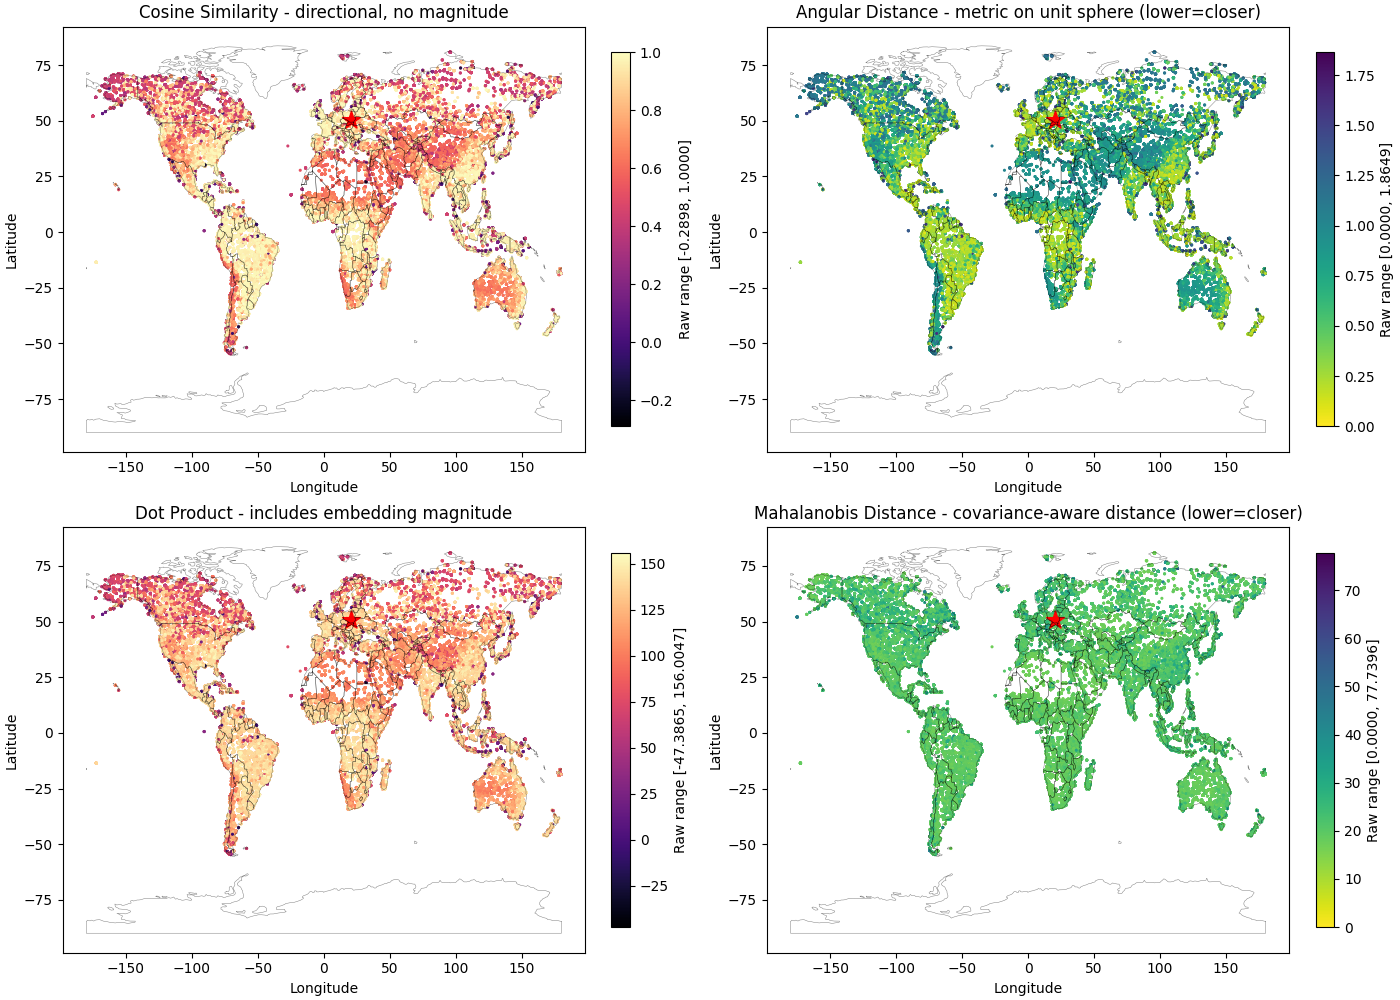

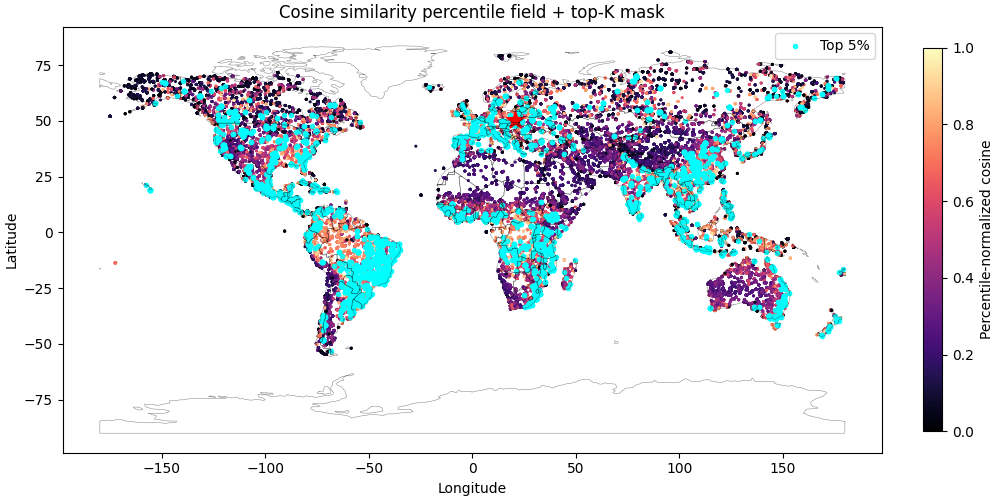

In [7]:
def _reference_geo() -> tuple[float, float]:
    if 0 <= selected_idx < len(lats):
        return float(lats[selected_idx]), float(lons[selected_idx])
    if region_indices.size > 0:
        return float(lats[region_indices].mean()), float(lons[region_indices].mean())
    return float(lats[0]), float(lons[0])

def plot_similarity_maps(ref: np.ndarray):
    cosine_raw = cosine_similarity(ref, E_norm)
    angular_raw = angular_distance(ref, E_norm)
    dot_raw = dot_product(ref, E)
    mahal_raw = mahalanobis_distance(ref, E, Sigma_inv)

    lat_ref, lon_ref = _reference_geo()

    panel_specs = [
        ("Cosine Similarity", cosine_raw, "magma", "directional, no magnitude"),
        ("Angular Distance", angular_raw, "viridis_r", "metric on unit sphere (lower=closer)"),
        ("Dot Product", dot_raw, "magma", "includes embedding magnitude"),
        ("Mahalanobis Distance", mahal_raw, "viridis_r", "covariance-aware distance (lower=closer)"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE, constrained_layout=True)
    for ax, (name, values, cmap, desc) in zip(axes.ravel(), panel_specs):
        sc = ax.scatter(lons, lats, c=values, s=5, cmap=cmap, linewidths=0)
        draw_world_outline(ax)
        ax.scatter([lon_ref], [lat_ref], color="red", marker="*", s=180, label="reference")
        if lasso_vertices is not None:
            closed = np.vstack([lasso_vertices, lasso_vertices[0]])
            ax.plot(closed[:, 0], closed[:, 1], color=REGION_SELECTION_COLOR, linewidth=1.8)
        ax.set_title(f"{name} - {desc}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        cbar = fig.colorbar(sc, ax=ax, shrink=0.88)
        cbar.set_label(f"Raw range [{values.min():.4f}, {values.max():.4f}]")

    plt.show()

    cosine_pct = percentile_normalize(cosine_raw)
    threshold = float(np.quantile(cosine_pct, 1.0 - (TOP_K_PERCENTILE / 100.0)))
    top_mask = cosine_pct >= threshold

    fig_pct, ax_pct = plt.subplots(1, 1, figsize=(10, 5), constrained_layout=True)
    sc_pct = ax_pct.scatter(lons, lats, c=cosine_pct, s=5, cmap="magma", linewidths=0)
    ax_pct.scatter(lons[top_mask], lats[top_mask], s=9, color="cyan", alpha=0.85, label=f"Top {TOP_K_PERCENTILE}%")
    draw_world_outline(ax_pct)
    ax_pct.scatter([lon_ref], [lat_ref], color="red", marker="*", s=180)
    if lasso_vertices is not None:
        closed = np.vstack([lasso_vertices, lasso_vertices[0]])
        ax_pct.plot(closed[:, 0], closed[:, 1], color=REGION_SELECTION_COLOR, linewidth=1.8)
    ax_pct.set_title("Cosine similarity percentile field + top-K mask")
    ax_pct.set_xlabel("Longitude")
    ax_pct.set_ylabel("Latitude")
    ax_pct.legend(loc="upper right")
    fig_pct.colorbar(sc_pct, ax=ax_pct, shrink=0.9, label="Percentile-normalized cosine")
    plt.show()

    return {
        "fields": {
            "cosine": cosine_raw,
            "angular_similarity": -angular_raw,
            "dot": dot_raw,
            "mahalanobis_similarity": -mahal_raw,
            "cosine_percentile": cosine_pct,
            "cosine_top_mask": top_mask.astype(np.uint8),
        },
        "main_fig": fig,
        "percentile_fig": fig_pct,
    }

latest_plot_bundle = plot_similarity_maps(ref_vector)

# TODO: add cosine-vs-mahalanobis delta map to highlight disagreement.

## 7. Quantitative Comparison of Measures

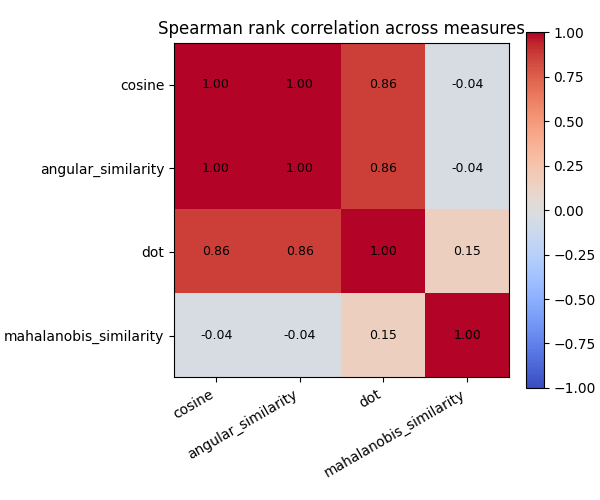

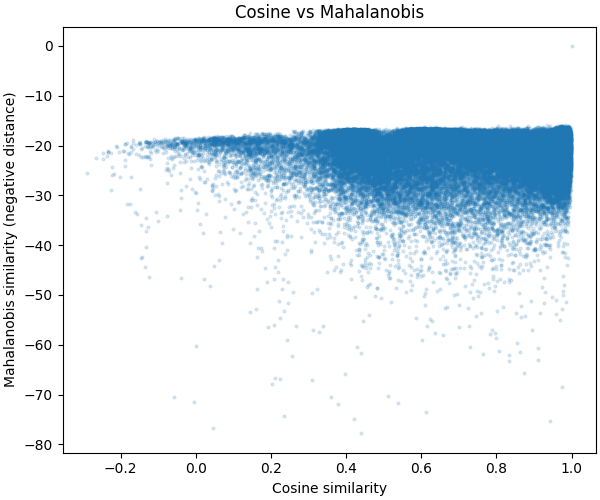

Biome labels not provided; skipping same-biome vs cross-biome comparison.


In [8]:
def measure_fields_for_reference(ref: np.ndarray) -> dict[str, np.ndarray]:
    cos = cosine_similarity(ref, E_norm)
    ang = angular_distance(ref, E_norm)
    dot = dot_product(ref, E)
    mah = mahalanobis_distance(ref, E, Sigma_inv)
    return {
        "cosine": cos,
        "angular_similarity": -ang,
        "dot": dot,
        "mahalanobis_similarity": -mah,
    }

comparison_fields = measure_fields_for_reference(ref_vector)
names = list(comparison_fields.keys())
corr = np.zeros((len(names), len(names)), dtype=np.float64)

for i, ni in enumerate(names):
    for j, nj in enumerate(names):
        corr[i, j] = spearmanr(comparison_fields[ni], comparison_fields[nj]).correlation

fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(names)), labels=names, rotation=30, ha="right")
ax.set_yticks(np.arange(len(names)), labels=names)
ax.set_title("Spearman rank correlation across measures")
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.9)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
ax.scatter(
    comparison_fields["cosine"],
    comparison_fields["mahalanobis_similarity"],
    s=4,
    alpha=0.15,
)
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Mahalanobis similarity (negative distance)")
ax.set_title("Cosine vs Mahalanobis")
plt.show()

if BIOME_PATH is not None and Path(BIOME_PATH).exists():
    biome_df = pd.read_csv(BIOME_PATH)
    if {"index", "biome"}.issubset(biome_df.columns):
        bdf = biome_df[["index", "biome"]].dropna()
        bdf = bdf[(bdf["index"] >= 0) & (bdf["index"] < len(E))].copy()
        idx = bdf["index"].astype(int).to_numpy()
        labels = bdf["biome"].astype(str).to_numpy()
        rng = np.random.default_rng(42)
        n_pairs = min(200_000, max(20_000, len(idx) * 10))
        ii = rng.integers(0, len(idx), size=n_pairs)
        jj = rng.integers(0, len(idx), size=n_pairs)
        same_mask = labels[ii] == labels[jj]
        valid = ii != jj
        same_mask = same_mask[valid]
        ii = ii[valid]
        jj = jj[valid]
        print("Biome separation summary (sampled pairs):")
        for key, values in comparison_fields.items():
            vi = values[idx[ii]]
            vj = values[idx[jj]]
            pair_score = 0.5 * (vi + vj)
            same_mean = float(pair_score[same_mask].mean())
            cross_mean = float(pair_score[~same_mask].mean())
            print(f"  {key}: same={same_mean:.4f}, cross={cross_mean:.4f}, gap={same_mean - cross_mean:.4f}")
    else:
        print("Biome file found, but expected columns {'index', 'biome'} are missing.")
else:
    print("Biome labels not provided; skipping same-biome vs cross-biome comparison.")

# TODO: formalize this as ROC/AUC for same-biome pair classification.

## 8. Save Results

In [9]:
if "latest_plot_bundle" not in globals():
    latest_plot_bundle = plot_similarity_maps(ref_vector)

fields = latest_plot_bundle["fields"]
ref_lat, ref_lon = _reference_geo()
tag = f"lat{ref_lat:+07.3f}_lon{ref_lon:+08.3f}".replace(".", "p")

for name, arr in fields.items():
    np.save(EXPORT_DIR / f"{tag}_{name}.npy", np.asarray(arr))

main_png = EXPORT_DIR / f"similarity_maps_4panel_{tag}.png"
pct_png = EXPORT_DIR / f"similarity_maps_percentile_{tag}.png"
latest_plot_bundle["main_fig"].savefig(main_png, dpi=300)
latest_plot_bundle["percentile_fig"].savefig(pct_png, dpi=300)

region_payload = {
    "indices": torch.from_numpy(region_indices.astype(np.int64)),
    "vectors": torch.from_numpy(region_vectors),
}
if lasso_vertices is not None:
    region_payload["lasso_vertices"] = torch.from_numpy(np.asarray(lasso_vertices, dtype=np.float32))

region_pt = EXPORT_DIR / f"selected_region_{tag}.pt"
torch.save(region_payload, region_pt)

print(f"Saved similarity arrays and figures to {EXPORT_DIR.resolve()}")
print(f"- Main 2x2 panel: {main_png.name}")
print(f"- Percentile panel: {pct_png.name}")
print(f"- Region selection: {region_pt.name}")

# TODO: export similarity fields as GeoTIFF for GIS workflows (rasterio).

Saved similarity arrays and figures to /home/micha-nowicki/repo/terramind/data/similarity_exports
- Main 2x2 panel: similarity_maps_4panel_lat+50p513_lon+020p513.png
- Percentile panel: similarity_maps_percentile_lat+50p513_lon+020p513.png
- Region selection: selected_region_lat+50p513_lon+020p513.pt
